# 🎯 YOLO11 Model Evaluation Report

Bu notebook, eğitilmiş YOLO11 modelinizi train/valid/test split'lerinden oluşan bir dataset üzerinde değerlendirmek ve tüm metrikleri kapsamlı biçimde raporlamak için tasarlanmıştır.

**Raporlanan Metrikler:**
- ✅ Precision / Recall / F1
- ✅ mAP@0.5 ve mAP@0.5:0.95
- ✅ Confusion Matrix
- ✅ PR Curve / F1-Confidence Curve
- ✅ Per-class sonuçlar
- ✅ Inference hızı (FPS / ms)
- ✅ Train vs Valid vs Test karşılaştırması
- ✅ CSV Export


---
## ⚙️ Bölüm 0 — Kurulum & Konfigürasyon

In [1]:
import os

# Notebook'un ana dizinini kaydet (sadece ilk çalıştırmada)
if 'NOTEBOOK_DIR' not in globals():
    NOTEBOOK_DIR = os.getcwd()

# Her zaman ana dizinden başla
os.chdir(NOTEBOOK_DIR)

# Yeni analiz klasörünü belirle
base_idx = 1
while os.path.exists(f"analiz{base_idx}"):
    base_idx += 1
base_dir = f"analiz{base_idx}"

# Klasörü oluştur ve içine gir
os.makedirs(base_dir, exist_ok=True)
os.chdir(base_dir)

print(f"✅ Yeni analiz başlatıldı. Çıktılar buraya kaydedilecek: {os.path.abspath('.')}")


✅ Yeni analiz başlatıldı. Çıktılar buraya kaydedilecek: c:\Users\ASUS\OneDrive\Masaüstü\Test\analiz5


In [2]:
# ============================================================
#  GEREKLİ KÜTÜPHANELERİ YÜKLE
# ============================================================
import subprocess, sys

def install_if_missing(pkg, import_name=None):
    import_name = import_name or pkg
    try:
        __import__(import_name)
    except ImportError:
        print(f"📦 {pkg} yükleniyor...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])
        print(f"✅ {pkg} yüklendi.")

install_if_missing("ultralytics")
install_if_missing("seaborn")
install_if_missing("matplotlib")
install_if_missing("scikit-learn", "sklearn")
install_if_missing("pandas")
install_if_missing("Pillow", "PIL")
install_if_missing("tqdm")

print("\n✅ Tüm bağımlılıklar hazır!")


✅ Tüm bağımlılıklar hazır!


In [3]:
# ============================================================
#  ⚠️  BURAYA KENDİ YOL VE SINIF BİLGİLERİNİZİ GİRİN
# ============================================================

# Model ağırlıkları (.pt dosyası)
MODEL_PATH = r"C:\Users\ASUS\Downloads\04.08_epoch130.pt"
#MODEL_PATH = r"C:\Users\ASUS\OneDrive\Masaüstü\Poyraz-takip\modeller\17temmuzSon.pt"            # ← kendi .pt dosyanızın yolunu girin

# Dataset kök klasörü (train/valid/test alt klasörlerini içermeli)
DATASET_PATH = r"C:\Users\ASUS\OneDrive\Masaüstü\dataset"           # ← kendi dataset klasörünüzün yolunu girin

# Sınıf isimleri (YOLO label sırasına göre)
CLASS_NAMES = ["ucak"]           # ← kendi sınıf isimlerinizi yazın, örn: ["kisi", "araba"]

# Değerlendirme ayarları
CONF_THRESHOLD  = 0.25              # Confidence threshold
IOU_THRESHOLD   = 0.6               # NMS IoU threshold
IMGSZ           = 640               # Görüntü boyutu
DEVICE          = ""                # "" = otomatik (cuda varsa GPU, yoksa CPU)
BATCH_SIZE      = 16                # Batch boyutu

# Çıktı klasörü
OUTPUT_DIR      = "sonuclar"    # Grafik ve CSV'lerin kaydedileceği klasör

# ============================================================
print(f"🔧 MODEL    : {MODEL_PATH}")
print(f"🔧 DATASET  : {DATASET_PATH}")
print(f"🔧 SINIFLAR : {CLASS_NAMES}")
print(f"🔧 DEVICE   : {'auto' if DEVICE == '' else DEVICE}")

🔧 MODEL    : C:\Users\ASUS\Downloads\04.08_epoch130.pt
🔧 DATASET  : C:\Users\ASUS\OneDrive\Masaüstü\dataset
🔧 SINIFLAR : ['ucak']
🔧 DEVICE   : auto


In [4]:
# ============================================================
#  IMPORTS & SETUP
# ============================================================
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import yaml
from ultralytics import YOLO
import torch

warnings.filterwarnings("ignore")

# Matplotlib stil
plt.rcParams.update({
    "figure.facecolor": "#0d0d0d",
    "axes.facecolor"  : "#1a1a2e",
    "axes.edgecolor"  : "#444",
    "axes.labelcolor" : "#e0e0e0",
    "xtick.color"     : "#e0e0e0",
    "ytick.color"     : "#e0e0e0",
    "text.color"      : "#e0e0e0",
    "grid.color"      : "#2a2a3e",
    "grid.linestyle"  : "--",
    "font.family"     : "DejaVu Sans",
    "font.size"       : 11,
})
CMAP = sns.color_palette("viridis", as_cmap=True)
ACCENT = "#7c3aed"  # purple accent
COLORS = ["#7c3aed", "#06b6d4", "#10b981", "#f59e0b", "#ef4444", "#ec4899"]

# Çıktı klasörünü oluştur
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"📁 Çıktı klasörü: {os.path.abspath(OUTPUT_DIR)}")

# GPU bilgisi
if torch.cuda.is_available():
    print(f"🚀 GPU: {torch.cuda.get_device_name(0)}")
else:
    print("💻 CPU modunda çalışıyor")

📁 Çıktı klasörü: c:\Users\ASUS\OneDrive\Masaüstü\Test\analiz5\sonuclar
🚀 GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [5]:
# ============================================================
#  data.yaml OLUŞTUR (yoksa otomatik üretilir)
# ============================================================
DATASET_PATH = Path(DATASET_PATH).resolve()
yaml_path = DATASET_PATH / "data.yaml"

# ⚠️ Dataset klasörü var mı kontrol et
if not DATASET_PATH.exists():
    print(f"⚠️  UYARI: Dataset klasörü bulunamadı: {DATASET_PATH}")
    print("   Lütfen Bölüm 0'daki DATASET_PATH değişkenini doğru ayarlayın.")
    raise FileNotFoundError(f"Dataset klasörü bulunamadı: {DATASET_PATH}")

if not yaml_path.exists():
    yaml_path.parent.mkdir(parents=True, exist_ok=True)  # ← DÜZELTME: klasörü oluştur
    data_yaml = {
        "path" : str(DATASET_PATH),
        "train": "train/images",
        "val"  : "valid/images",
        "test" : "test/images",
        "nc"   : len(CLASS_NAMES),
        "names": CLASS_NAMES,
    }
    with open(yaml_path, "w") as f:
        yaml.dump(data_yaml, f, default_flow_style=False, allow_unicode=True)
    print(f"✅ data.yaml oluşturuldu: {yaml_path}")
else:
    print(f"✅ Mevcut data.yaml kullanılıyor: {yaml_path}")
    with open(yaml_path) as f:
        cfg = yaml.safe_load(f)
    CLASS_NAMES = cfg.get("names", CLASS_NAMES)
    print(f"   Sınıflar: {CLASS_NAMES}")


✅ Mevcut data.yaml kullanılıyor: C:\Users\ASUS\OneDrive\Masaüstü\dataset\data.yaml
   Sınıflar: ['ucak']


---
## 📊 Bölüm 1 — Dataset Keşfi

In [6]:
# ============================================================
#  SPLIT BAZINDA GÖRÜNTÜ / LABEL SAYISI
# ============================================================
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp'}

def count_split(split_name):
    split_dir = DATASET_PATH / split_name
    img_dir   = split_dir / "images"
    lbl_dir   = split_dir / "labels"
    imgs  = [f for f in img_dir.glob("*") if f.suffix.lower() in IMG_EXTS] if img_dir.exists() else []
    lbls  = list(lbl_dir.glob("*.txt")) if lbl_dir.exists() else []
    return len(imgs), len(lbls)

splits = ["train", "valid", "test"]
split_data = {}
for s in splits:
    ni, nl = count_split(s)
    split_data[s] = {"images": ni, "labels": nl}
    print(f"  [{s:>5}]  🖼  {ni:>5} görüntü   🏷  {nl:>5} label")

total_imgs = sum(v["images"] for v in split_data.values())
print(f"\n  TOPLAM: {total_imgs} görüntü")

  [train]  🖼  10115 görüntü   🏷  10115 label
  [valid]  🖼   1264 görüntü   🏷   1264 label
  [ test]  🖼   1265 görüntü   🏷   1265 label

  TOPLAM: 12644 görüntü


In [7]:
# ============================================================
#  SINIF DAĞILIMI — tüm split'ler
# ============================================================
def parse_labels(split_name):
    """Her sınıf için toplam nesne sayısını döndürür."""
    lbl_dir = DATASET_PATH / split_name / "labels"
    counts  = np.zeros(len(CLASS_NAMES), dtype=int)
    if not lbl_dir.exists():
        return counts
    for f in lbl_dir.glob("*.txt"):
        try:
            data = np.loadtxt(f, ndmin=2)
            for row in data:
                cls = int(row[0])
                if 0 <= cls < len(CLASS_NAMES):
                    counts[cls] += 1
        except Exception:
            pass
    return counts

class_counts = {s: parse_labels(s) for s in splits}

# DataFrame
df_cls = pd.DataFrame(class_counts, index=CLASS_NAMES)
df_cls["TOPLAM"] = df_cls.sum(axis=1)
print("\n📋 Sınıf Dağılımı:")
display(df_cls.style.background_gradient(cmap="viridis", subset=["TOPLAM"]))


📋 Sınıf Dağılımı:


,train,valid,test,TOPLAM
ucak,9821,1227,1160,12208


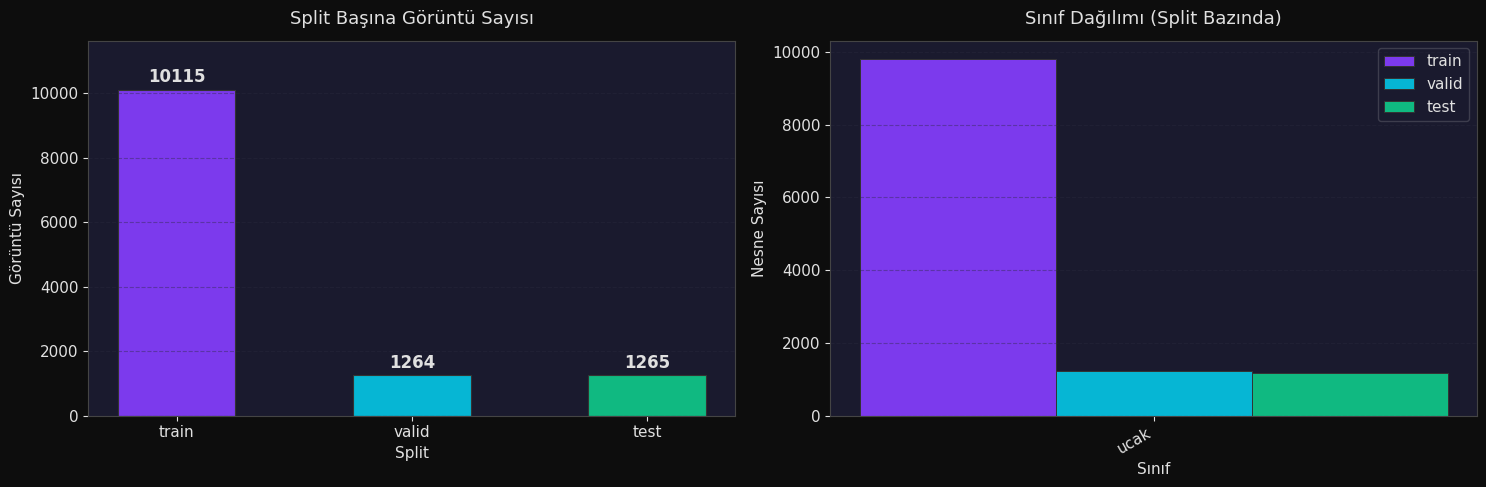

✅ Grafik kaydedildi.


In [8]:
# ============================================================
#  GRAFİK — Split başına görüntü sayısı & sınıf dağılımı
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.patch.set_facecolor("#0d0d0d")

# Sol: Split başına görüntü sayısı
ax = axes[0]
img_counts = [split_data[s]["images"] for s in splits]
bars = ax.bar(splits, img_counts, color=COLORS[:3], width=0.5, edgecolor="#333", linewidth=0.8)
for bar, val in zip(bars, img_counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(img_counts)*0.01,
            str(val), ha="center", va="bottom", fontsize=12, fontweight="bold", color="#e0e0e0")
ax.set_title("Split Başına Görüntü Sayısı", fontsize=13, pad=12)
ax.set_xlabel("Split")
ax.set_ylabel("Görüntü Sayısı")
ax.set_ylim(0, max(img_counts) * 1.15)
ax.grid(axis="y", alpha=0.4)

# Sağ: Sınıf dağılımı (stacked)
ax2 = axes[1]
x  = np.arange(len(CLASS_NAMES))
width = 0.25
for i, (sp, color) in enumerate(zip(splits, COLORS)):
    ax2.bar(x + i*width, class_counts[sp], width=width, label=sp, color=color,
            edgecolor="#333", linewidth=0.7)
ax2.set_title("Sınıf Dağılımı (Split Bazında)", fontsize=13, pad=12)
ax2.set_xlabel("Sınıf")
ax2.set_ylabel("Nesne Sayısı")
ax2.set_xticks(x + width)
ax2.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
ax2.legend(framealpha=0.2)
ax2.grid(axis="y", alpha=0.4)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/dataset_overview.png", dpi=150, bbox_inches="tight",
            facecolor=fig.get_facecolor())
plt.show()
print("✅ Grafik kaydedildi.")

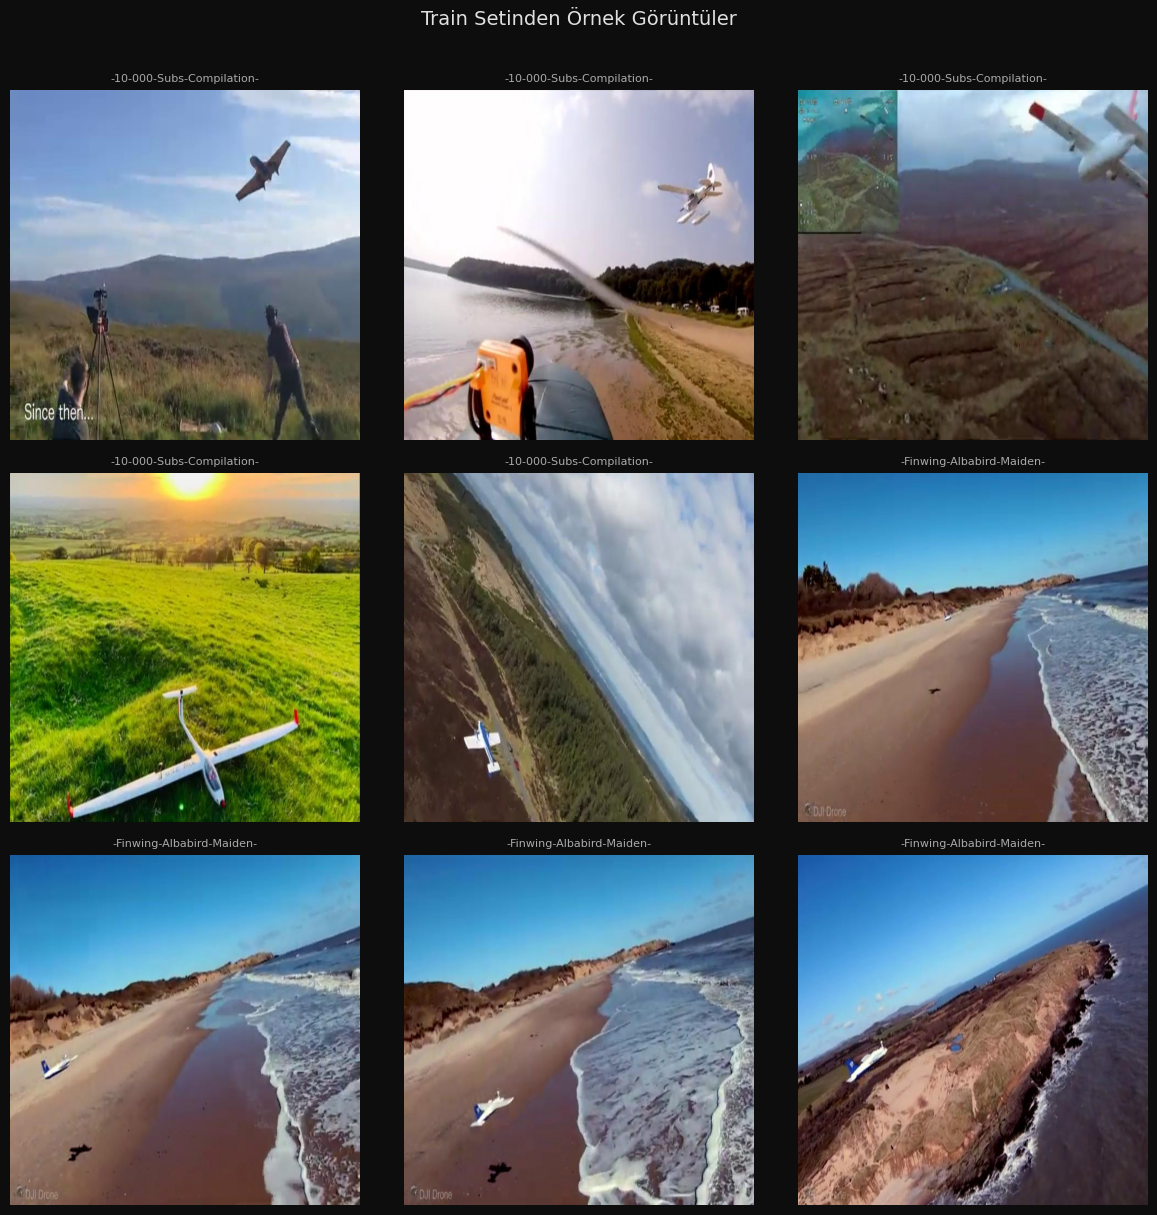

In [9]:
# ============================================================
#  ÖRNEK GÖRÜNTÜLERİ GÖSTER (train setinden 9 görüntü)
# ============================================================
img_dir = DATASET_PATH / "train" / "images"
sample_imgs = [f for f in img_dir.glob("*") if f.suffix.lower() in IMG_EXTS][:9]

if sample_imgs:
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    fig.patch.set_facecolor("#0d0d0d")
    fig.suptitle("Train Setinden Örnek Görüntüler", fontsize=14, color="#e0e0e0", y=1.01)
    for ax, img_path in zip(axes.flat, sample_imgs):
        img = Image.open(img_path).convert("RGB")
        ax.imshow(img)
        ax.set_title(img_path.name[:25], fontsize=8, color="#aaa")
        ax.axis("off")
    for ax in axes.flat[len(sample_imgs):]:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/sample_images.png", dpi=100, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
else:
    print("⚠️  Train görüntüleri bulunamadı.")

---
## 🤖 Bölüm 2 — Model Yükleme & Bilgisi

In [10]:
# ============================================================
#  MODEL YÜKLE
# ============================================================
print(f"📂 Model yükleniyor: {MODEL_PATH}")
model = YOLO(MODEL_PATH)
print("✅ Model başarıyla yüklendi!\n")

# Model bilgisi
info = model.info(verbose=False)

# PyTorch parametre sayısı
total_params   = sum(p.numel() for p in model.model.parameters())
trainable_params = sum(p.numel() for p in model.model.parameters() if p.requires_grad)

print(f"{'='*50}")
print(f"  Model Tipi         : YOLO11 Object Detection")
print(f"  Sınıf Sayısı       : {model.model.nc}")
print(f"  Toplam Parametre   : {total_params:,}")
print(f"  Eğitilebilir Param : {trainable_params:,}")
print(f"  Görüntü Boyutu     : {IMGSZ}")
print(f"{'='*50}")

📂 Model yükleniyor: C:\Users\ASUS\Downloads\04.08_epoch130.pt
✅ Model başarıyla yüklendi!

  Model Tipi         : YOLO11 Object Detection
  Sınıf Sayısı       : 1
  Toplam Parametre   : 9,428,179
  Eğitilebilir Param : 0
  Görüntü Boyutu     : 640


In [11]:
# ============================================================
#  MODEL BİLGİSİ GÖRSELLEŞTİRME
# ============================================================
model_info_df = pd.DataFrame({
    "Özellik" : ["Model Dosyası", "Sınıf Sayısı", "Sınıflar",
                 "Toplam Parametre", "Eğitilebilir Parametre",
                 "Görüntü Boyutu", "Confidence Threshold", "IoU Threshold"],
    "Değer"   : [
        Path(MODEL_PATH).name,
        model.model.nc,
        ", ".join(CLASS_NAMES),
        f"{total_params:,}",
        f"{trainable_params:,}",
        IMGSZ,
        CONF_THRESHOLD,
        IOU_THRESHOLD,
    ]
})
display(model_info_df.style.set_properties(**{"text-align": "left"}).hide(axis="index"))

Özellik,Değer
Model Dosyası,04.08_epoch130.pt
Sınıf Sayısı,1
Sınıflar,ucak
Toplam Parametre,"9,428,179"
Eğitilebilir Parametre,0
Görüntü Boyutu,640
Confidence Threshold,0.250000
IoU Threshold,0.600000


---
## 📐 Bölüm 3 — Validation Seti Değerlendirmesi

In [12]:
# ============================================================
#  VALIDATION SET — model.val()
# ============================================================
print("🔍 Validation seti değerlendiriliyor...\n")

val_results = model.val(
    data    = str(yaml_path),
    split   = "val",
    imgsz   = IMGSZ,
    conf    = CONF_THRESHOLD,
    iou     = IOU_THRESHOLD,
    batch   = BATCH_SIZE,
    device  = DEVICE,
    plots   = True,
    save_json = False,
    verbose = True,
)

print("\n✅ Validation değerlendirmesi tamamlandı!")

🔍 Validation seti değerlendiriliyor...

Ultralytics 8.4.51  Python-3.10.20 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11s summary (fused): 101 layers, 9,413,187 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access  (ping: 0.20.1 ms, read: 49.432.3 MB/s, size: 32.0 KB)
val: Scanning C:\Users\ASUS\OneDrive\Masaüstü\dataset\valid\labels.cache... 1264 images, 162 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1264/1264  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 79/79 2.0it/s 39.1s0.4ss
                   all       1264       1227      0.921      0.901      0.902      0.649
Speed: 4.0ms preprocess, 18.5ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to C:\Users\ASUS\OneDrive\Masast\Test\analiz5\runs\detect\val

✅ Validation değerlendirmesi tamamlandı!


In [13]:
# ============================================================
#  VALİDATİON METRİKLERİNİ ÇIKAR
# ============================================================
def extract_metrics(results, split_name):
    """Ultralytics val results nesnesinden metrikleri dict olarak çıkarır."""
    mp  = float(results.box.mp)          # Mean Precision
    mr  = float(results.box.mr)          # Mean Recall
    map50   = float(results.box.map50)   # mAP@0.5
    map5095 = float(results.box.map)     # mAP@0.5:0.95

    # F1 = 2 * P * R / (P + R)
    f1 = 2 * mp * mr / (mp + mr + 1e-9)

    # Hız metrikleri (ms)
    speed = results.speed  # dict: preprocess, inference, postprocess

    return {
        "Split"           : split_name,
        "Precision"       : round(mp, 4),
        "Recall"          : round(mr, 4),
        "F1"              : round(f1, 4),
        "mAP@0.5"         : round(map50, 4),
        "mAP@0.5:0.95"    : round(map5095, 4),
        "Preprocess (ms)" : round(speed.get("preprocess", 0), 2),
        "Inference (ms)"  : round(speed.get("inference", 0), 2),
        "Postprocess (ms)": round(speed.get("postprocess", 0), 2),
    }

val_metrics = extract_metrics(val_results, "valid")

print(f"\n📊 Validation Metrikleri:")
for k, v in val_metrics.items():
    print(f"   {k:<20}: {v}")


📊 Validation Metrikleri:
   Split               : valid
   Precision           : 0.9208
   Recall              : 0.9006
   F1                  : 0.9106
   mAP@0.5             : 0.9016
   mAP@0.5:0.95        : 0.6489
   Preprocess (ms)     : 4.0
   Inference (ms)      : 18.55
   Postprocess (ms)    : 1.9


In [14]:
# ============================================================
#  PER-CLASS SONUÇLAR
# ============================================================
def per_class_metrics(results, split_name):
    """Her sınıf için P/R/F1/mAP tablosu."""
    ap_class = results.box.ap_class_index.tolist() if hasattr(results.box, 'ap_class_index') else list(range(len(CLASS_NAMES)))
    aps50    = results.box.ap50.tolist()   if hasattr(results.box, 'ap50')   else []
    aps5095  = results.box.ap.tolist()     if hasattr(results.box, 'ap')     else []
    ps       = results.box.p.tolist()      if hasattr(results.box, 'p')      else []
    rs       = results.box.r.tolist()      if hasattr(results.box, 'r')      else []

    rows = []
    for i, cls_idx in enumerate(ap_class):
        p  = ps[i]    if i < len(ps)    else float('nan')
        r  = rs[i]    if i < len(rs)    else float('nan')
        f1 = 2*p*r/(p+r+1e-9)
        a50   = aps50[i]   if i < len(aps50)   else float('nan')
        a5095 = aps5095[i] if i < len(aps5095) else float('nan')
        name  = CLASS_NAMES[cls_idx] if cls_idx < len(CLASS_NAMES) else f"class_{cls_idx}"
        rows.append({
            "Sınıf"        : name,
            "Precision"    : round(p, 4),
            "Recall"       : round(r, 4),
            "F1"           : round(f1, 4),
            "mAP@0.5"      : round(a50, 4),
            "mAP@0.5:0.95" : round(a5095, 4),
        })

    df = pd.DataFrame(rows)
    return df

df_val_cls = per_class_metrics(val_results, "valid")
print(f"\n📋 Per-Class Metrikler — Validation:")
display(df_val_cls.style.background_gradient(cmap="RdYlGn",
        subset=["Precision","Recall","F1","mAP@0.5","mAP@0.5:0.95"]))


📋 Per-Class Metrikler — Validation:


,Sınıf,Precision,Recall,F1,mAP@0.5,mAP@0.5:0.95
0,ucak,0.920800,0.900600,0.910600,0.901600,0.648900


In [15]:
# ============================================================
#  ULTRALYTICS GRAFİKLERİNİ GÖSTER (Confusion Matrix, PR, F1)
# ============================================================
import glob

# Ultralytics grafikleri runs/ altına kaydeder
runs_dir = Path("runs")
plot_names = ["confusion_matrix", "PR_curve", "F1_curve",
              "P_curve", "R_curve", "labels"]

def find_latest_plot(name):
    """runs/ altında en yeni grafik dosyasını bulur."""
    pattern = str(runs_dir / "**" / f"{name}.png")
    files   = glob.glob(pattern, recursive=True)
    if files:
        return max(files, key=os.path.getmtime)
    return None

found_plots = {}
for pname in plot_names:
    path = find_latest_plot(pname)
    if path:
        found_plots[pname] = path
        print(f"✅ {pname}: {path}")
    else:
        print(f"⚠️  {pname}: bulunamadı")

✅ confusion_matrix: runs\detect\val\confusion_matrix.png
⚠️  PR_curve: bulunamadı
⚠️  F1_curve: bulunamadı
⚠️  P_curve: bulunamadı
⚠️  R_curve: bulunamadı
⚠️  labels: bulunamadı


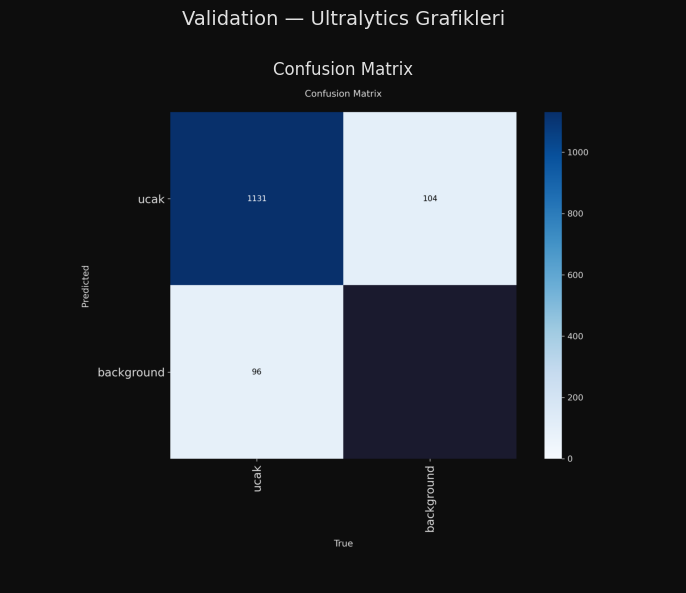

In [16]:
# ============================================================
#  GRAFİKLERİ GÖSTERiMLE AÇ
# ============================================================
cols_to_show = ["confusion_matrix", "PR_curve", "F1_curve", "P_curve", "R_curve"]
available    = [c for c in cols_to_show if c in found_plots]

if available:
    n = len(available)
    ncols = min(n, 3)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 6 * nrows))
    fig.patch.set_facecolor("#0d0d0d")
    axes_flat = axes.flat if n > 1 else [axes]

    for ax, name in zip(axes_flat, available):
        img = Image.open(found_plots[name]).convert("RGB")
        ax.imshow(img)
        ax.set_title(name.replace("_", " ").title(), fontsize=12)
        ax.axis("off")

    for ax in list(axes_flat)[len(available):]:
        ax.axis("off")

    plt.suptitle("Validation — Ultralytics Grafikleri", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/val_curves.png", dpi=120, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
else:
    print("⚠️  Gösterilecek grafik bulunamadı.")

---
## 🎯 Bölüm 3.5 — Boyut Bazlı Performans Analizi (Savaşan İHA Senaryosu)

Bu bölüm, **nesne boyutuna göre** model başarısını analiz eder.  
Savaşan İHA senaryosunda en kritik soru: *küçük hedefleri kaçırıyor muyuz?*

| Grup | Piksel Aralığı | Açıklama |
|------|----------------|----------|
| Çok Küçük | 0–16 px | Uzak mesafe hedefler |
| Küçük | 16–32 px | Küçük hedefler |
| Orta | 32–64 px | Orta mesafe |
| Büyük | 64+ px | Yakın mesafe |

> **Not:** Boyut = `max(genişlik, yükseklik)` piksel cinsinden hesaplanır.

In [17]:
# ============================================================
#  BOYUT BAZLI ANALİZ — Yardımcı Fonksiyonlar
# ============================================================

SIZE_BINS = [
    ("0-16 px (Çok Küçük)",  0,  16),
    ("16-32 px (Küçük)",    16,  32),
    ("32-64 px (Orta)",     32,  64),
    ("64+ px (Büyük)",      64,  float("inf")),
]

def compute_iou(box1, box2):
    """İki [x1,y1,x2,y2] kutusu arasında IoU hesaplar."""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - inter
    return inter / (union + 1e-9)

def yolo_to_xyxy(cx, cy, w, h, img_w, img_h):
    """YOLO normalize formatından piksel [x1,y1,x2,y2] formatına çevirir."""
    x1 = (cx - w / 2) * img_w
    y1 = (cy - h / 2) * img_h
    x2 = (cx + w / 2) * img_w
    y2 = (cy + h / 2) * img_h
    return [x1, y1, x2, y2]

def get_box_max_dim(box):
    """[x1,y1,x2,y2] kutusundan max(w,h) piksel değerini döndürür."""
    return max(box[2] - box[0], box[3] - box[1])

def get_size_group(max_dim):
    """Piksel boyutuna göre boyut grubunu döndürür."""
    for name, lo, hi in SIZE_BINS:
        if lo <= max_dim < hi:
            return name
    return SIZE_BINS[-1][0]

print("✅ Boyut analizi yardımcı fonksiyonları hazır.")

✅ Boyut analizi yardımcı fonksiyonları hazır.


In [18]:
# ============================================================
#  BOYUT BAZLI ANALİZ — Ana Fonksiyon
# ============================================================

def size_based_analysis(model, split_name, dataset_path, class_names,
                        imgsz, conf_threshold, iou_threshold, device):
    """
    Her boyut grubu için Precision / Recall / F1 / mAP hesaplar.
    Ground truth label'ları ve model prediction'larını karşılaştırır.
    """
    img_dir = dataset_path / split_name / "images"
    lbl_dir = dataset_path / split_name / "labels"

    if not img_dir.exists():
        print(f"⚠️  {split_name} split bulunamadı.")
        return None, None

    img_files = sorted([f for f in img_dir.glob("*")
                        if f.suffix.lower() in IMG_EXTS])

    if not img_files:
        print(f"⚠️  {split_name} split içinde görüntü bulunamadı.")
        return None, None

    # Boyut grubu bazlı sayaçlar
    group_detections = {name: [] for name, _, _ in SIZE_BINS}
    group_gt_count   = {name: 0  for name, _, _ in SIZE_BINS}
    group_tp = {name: 0 for name, _, _ in SIZE_BINS}
    group_fp = {name: 0 for name, _, _ in SIZE_BINS}
    group_fn = {name: 0 for name, _, _ in SIZE_BINS}
    all_gt_sizes = []

    for img_path in tqdm(img_files, desc=f"📐 Boyut analizi ({split_name})"):
        lbl_path = lbl_dir / (img_path.stem + ".txt")

        # Görüntü boyutlarını al
        try:
            with Image.open(img_path) as im:
                img_w, img_h = im.size
        except Exception:
            continue

        # Ground truth parse et
        gt_boxes = []
        if lbl_path.exists():
            try:
                data = np.loadtxt(lbl_path, ndmin=2)
                for row in data:
                    cls = int(row[0])
                    if cls < len(class_names):
                        xyxy = yolo_to_xyxy(row[1], row[2], row[3], row[4],
                                            img_w, img_h)
                        max_dim = get_box_max_dim(xyxy)
                        sg = get_size_group(max_dim)
                        gt_boxes.append({"box": xyxy, "group": sg,
                                         "matched": False,
                                         "max_dim": max_dim})
                        group_gt_count[sg] += 1
                        all_gt_sizes.append(max_dim)
            except Exception:
                pass

        # Model prediction
        results = model.predict(str(img_path), imgsz=imgsz,
                               conf=conf_threshold,
                               device=device, verbose=False)

        pred_list = []
        if results and results[0].boxes is not None and len(results[0].boxes) > 0:
            boxes = results[0].boxes
            for i in range(len(boxes)):
                xyxy = boxes.xyxy[i].cpu().numpy().tolist()
                conf = float(boxes.conf[i])
                pred_list.append({"box": xyxy, "conf": conf})
            pred_list.sort(key=lambda x: x["conf"], reverse=True)

        # IoU eşleştirmesi
        for pred in pred_list:
            best_iou = 0
            best_gt_idx = -1
            for j, gt in enumerate(gt_boxes):
                if gt["matched"]:
                    continue
                iou_val = compute_iou(pred["box"], gt["box"])
                if iou_val > best_iou:
                    best_iou = iou_val
                    best_gt_idx = j

            if best_iou >= iou_threshold and best_gt_idx >= 0:
                # True Positive
                sg = gt_boxes[best_gt_idx]["group"]
                gt_boxes[best_gt_idx]["matched"] = True
                group_tp[sg] += 1
                group_detections[sg].append((pred["conf"], True))
            else:
                # False Positive
                pred_max_dim = get_box_max_dim(pred["box"])
                sg = get_size_group(pred_max_dim)
                group_fp[sg] += 1
                group_detections[sg].append((pred["conf"], False))

        # False Negative (eşleşmeyen GT)
        for gt in gt_boxes:
            if not gt["matched"]:
                group_fn[gt["group"]] += 1

    # === Metrik Hesaplama ===
    rows = []
    for name, lo, hi in SIZE_BINS:
        tp = group_tp[name]
        fp = group_fp[name]
        fn = group_fn[name]
        n_gt = group_gt_count[name]

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall + 1e-9) \
             if (precision + recall) > 0 else 0.0

        # AP hesaplama (all-point interpolation)
        ap = 0.0
        dets = group_detections[name]
        if dets and n_gt > 0:
            dets.sort(key=lambda x: x[0], reverse=True)
            tp_cum, fp_cum = 0, 0
            precisions_list, recalls_list = [], []
            for conf_val, is_tp in dets:
                if is_tp:
                    tp_cum += 1
                else:
                    fp_cum += 1
                precisions_list.append(tp_cum / (tp_cum + fp_cum))
                recalls_list.append(tp_cum / n_gt)

            mrec = [0.0] + recalls_list + [1.0]
            mpre = [0.0] + precisions_list + [0.0]
            for i in range(len(mpre) - 2, -1, -1):
                mpre[i] = max(mpre[i], mpre[i + 1])
            for i in range(1, len(mrec)):
                if mrec[i] != mrec[i - 1]:
                    ap += (mrec[i] - mrec[i - 1]) * mpre[i]

        rows.append({
            "Split": split_name,
            "Boyut Grubu": name,
            "GT Sayısı": n_gt,
            "TP": tp, "FP": fp, "FN": fn,
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1": round(f1, 4),
            "mAP@0.5": round(ap, 4),
        })

    return pd.DataFrame(rows), np.array(all_gt_sizes)

print("✅ Boyut bazlı analiz fonksiyonu hazır.")

✅ Boyut bazlı analiz fonksiyonu hazır.


In [19]:
# ============================================================
#  BOYUT DAĞILIMI & VALİDATİON ANALİZİ
# ============================================================

# Validation split üzerinde boyut bazlı analiz
print("🔍 Validation seti boyut bazlı analiz ediliyor...\n")
df_size_val, gt_sizes_val = size_based_analysis(
    model, "valid", DATASET_PATH, CLASS_NAMES,
    IMGSZ, CONF_THRESHOLD, IOU_THRESHOLD, DEVICE
)

# Test split üzerinde boyut bazlı analiz
test_img_dir_check = DATASET_PATH / "test" / "images"
df_size_test = None
gt_sizes_test = None
if test_img_dir_check.exists() and len(list(test_img_dir_check.glob("*"))) > 0:
    print("\n🔍 Test seti boyut bazlı analiz ediliyor...\n")
    df_size_test, gt_sizes_test = size_based_analysis(
        model, "test", DATASET_PATH, CLASS_NAMES,
        IMGSZ, CONF_THRESHOLD, IOU_THRESHOLD, DEVICE
    )

print("\n✅ Boyut bazlı analiz tamamlandı!")

🔍 Validation seti boyut bazlı analiz ediliyor...



📐 Boyut analizi (valid): 100%|██████████| 1264/1264 [00:55<00:00, 22.62it/s]



🔍 Test seti boyut bazlı analiz ediliyor...



📐 Boyut analizi (test): 100%|██████████| 1265/1265 [00:58<00:00, 21.68it/s]



✅ Boyut bazlı analiz tamamlandı!


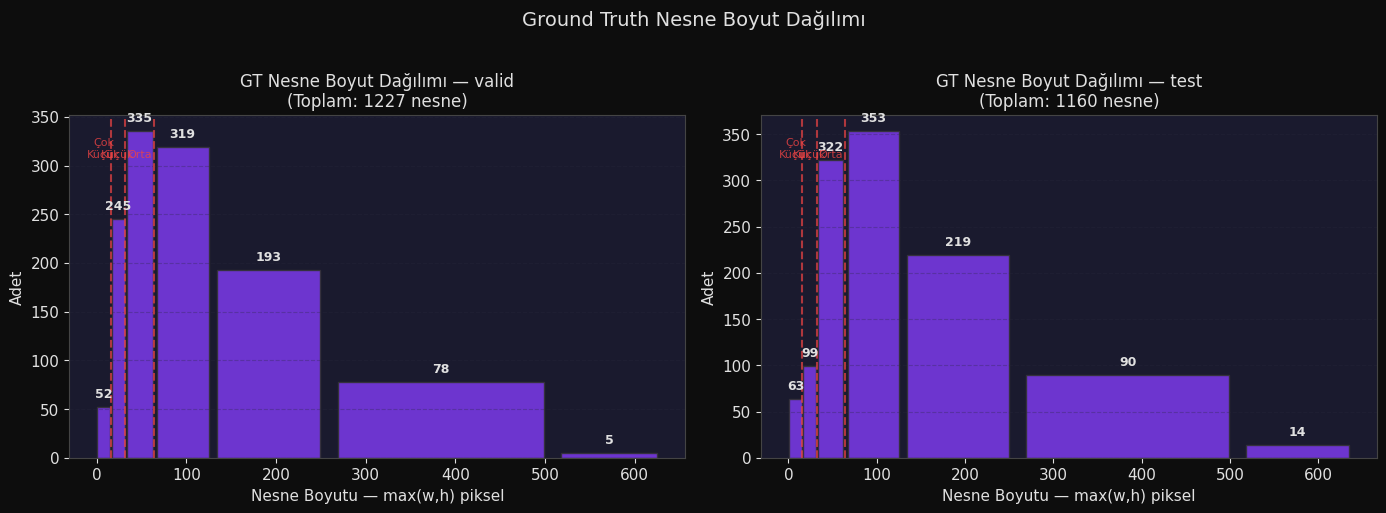

In [20]:
# ============================================================
#  BOYUT DAĞILIMI HİSTOGRAMI
# ============================================================

# Tüm split'lerden boyut verilerini birleştir
all_sizes_combined = []
size_labels = []
if gt_sizes_val is not None and len(gt_sizes_val) > 0:
    all_sizes_combined.append(gt_sizes_val)
    size_labels.append("valid")
if gt_sizes_test is not None and len(gt_sizes_test) > 0:
    all_sizes_combined.append(gt_sizes_test)
    size_labels.append("test")

if all_sizes_combined:
    fig, axes = plt.subplots(1, len(all_sizes_combined),
                            figsize=(7 * len(all_sizes_combined), 5))
    fig.patch.set_facecolor("#0d0d0d")

    if len(all_sizes_combined) == 1:
        axes = [axes]

    bin_edges = [0, 16, 32, 64, 128, 256, 512]
    bin_labels = ["0-16", "16-32", "32-64", "64-128", "128-256", "256-512"]

    for ax, sizes, label in zip(axes, all_sizes_combined, size_labels):
        # Boyut grubu sınırlarını belirle
        max_val = max(sizes.max(), 512)
        edges = [e for e in bin_edges if e <= max_val]
        if edges[-1] < max_val:
            edges.append(int(max_val) + 1)

        counts, _, bars = ax.hist(sizes, bins=edges,
                                  color=ACCENT, edgecolor="#333",
                                  alpha=0.85, rwidth=0.9)

        # Boyut grubu sınır çizgileri
        for boundary in [16, 32, 64]:
            ax.axvline(x=boundary, color="#ef4444", linestyle="--",
                       linewidth=1.5, alpha=0.7)

        # Bar üstüne sayılar
        for bar_obj, count in zip(bars, counts):
            if count > 0:
                ax.text(bar_obj.get_x() + bar_obj.get_width() / 2,
                        bar_obj.get_height() + max(counts) * 0.02,
                        f"{int(count)}", ha="center", va="bottom",
                        fontsize=9, color="#e0e0e0", fontweight="bold")

        ax.set_xlabel("Nesne Boyutu — max(w,h) piksel", fontsize=11)
        ax.set_ylabel("Adet", fontsize=11)
        ax.set_title(f"GT Nesne Boyut Dağılımı — {label}\n"
                     f"(Toplam: {len(sizes)} nesne)", fontsize=12)
        ax.grid(axis="y", alpha=0.3)

        # Boyut grubu etiketleri
        ax.text(8,  max(counts) * 0.92, "Çok\nKüçük",
                ha="center", fontsize=8, color="#ef4444", alpha=0.8)
        ax.text(24, max(counts) * 0.92, "Küçük",
                ha="center", fontsize=8, color="#ef4444", alpha=0.8)
        ax.text(48, max(counts) * 0.92, "Orta",
                ha="center", fontsize=8, color="#ef4444", alpha=0.8)

    plt.suptitle("Ground Truth Nesne Boyut Dağılımı",
                 fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/size_distribution.png", dpi=150,
                bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()
else:
    print("⚠️  Boyut dağılımı gösterilecek veri bulunamadı.")

In [21]:
# ============================================================
#  BOYUT BAZLI METRİK TABLOSU
# ============================================================

size_dfs = []
if df_size_val is not None:
    size_dfs.append(df_size_val)
if df_size_test is not None:
    size_dfs.append(df_size_test)

if size_dfs:
    df_size_all = pd.concat(size_dfs, ignore_index=True)

    print("\n📊 Boyut Bazlı Performans Tablosu:")
    print("=" * 70)
    metric_cols_size = [c for c in ["Precision", "Recall", "F1", "mAP@0.5"]
                        if c in df_size_all.columns]
    display(df_size_all.style.background_gradient(
        cmap="RdYlGn", subset=metric_cols_size
    ).format({c: "{:.4f}" for c in metric_cols_size}))

    # --- Uyarı mesajları ---
    print("\n⚠️  KRİTİK BULGULAR:")
    for _, row in df_size_all.iterrows():
        if row["Recall"] < 0.5 and row["GT Sayısı"] > 0:
            print(f'   🔴 {row["Split"]} / {row["Boyut Grubu"]}: '
                  f'Recall = {row["Recall"]:.4f} — '
                  f'{row["FN"]} / {row["GT Sayısı"]} hedef KAÇIRILDI!')
        elif row["Recall"] < 0.8 and row["GT Sayısı"] > 0:
            print(f'   🟡 {row["Split"]} / {row["Boyut Grubu"]}: '
                  f'Recall = {row["Recall"]:.4f} — dikkat gerekli')
        elif row["GT Sayısı"] > 0:
            print(f'   🟢 {row["Split"]} / {row["Boyut Grubu"]}: '
                  f'Recall = {row["Recall"]:.4f} — iyi')
else:
    print("⚠️  Boyut bazlı analiz sonucu bulunamadı.")
    df_size_all = None


📊 Boyut Bazlı Performans Tablosu:


,Split,Boyut Grubu,GT Sayısı,TP,FP,FN,Precision,Recall,F1,mAP@0.5
0,valid,0-16 px (Çok Küçük),52,27,47,25,0.3649,0.5192,0.4286,0.3097
1,valid,16-32 px (Küçük),245,194,44,51,0.8151,0.7918,0.8033,0.7317
2,valid,32-64 px (Orta),335,295,22,40,0.9306,0.8806,0.9049,0.8687
3,valid,64+ px (Büyük),595,562,60,33,0.9035,0.9445,0.9236,0.9377
4,test,0-16 px (Çok Küçük),63,49,24,14,0.6712,0.7778,0.7206,0.6744
5,test,16-32 px (Küçük),99,74,40,25,0.6491,0.7475,0.6948,0.7007
6,test,32-64 px (Orta),322,300,133,22,0.6928,0.9317,0.7947,0.9119
7,test,64+ px (Büyük),676,622,69,54,0.9001,0.9201,0.9100,0.9152



⚠️  KRİTİK BULGULAR:
   🟡 valid / 0-16 px (Çok Küçük): Recall = 0.5192 — dikkat gerekli
   🟡 valid / 16-32 px (Küçük): Recall = 0.7918 — dikkat gerekli
   🟢 valid / 32-64 px (Orta): Recall = 0.8806 — iyi
   🟢 valid / 64+ px (Büyük): Recall = 0.9445 — iyi
   🟡 test / 0-16 px (Çok Küçük): Recall = 0.7778 — dikkat gerekli
   🟡 test / 16-32 px (Küçük): Recall = 0.7475 — dikkat gerekli
   🟢 test / 32-64 px (Orta): Recall = 0.9317 — iyi
   🟢 test / 64+ px (Büyük): Recall = 0.9201 — iyi


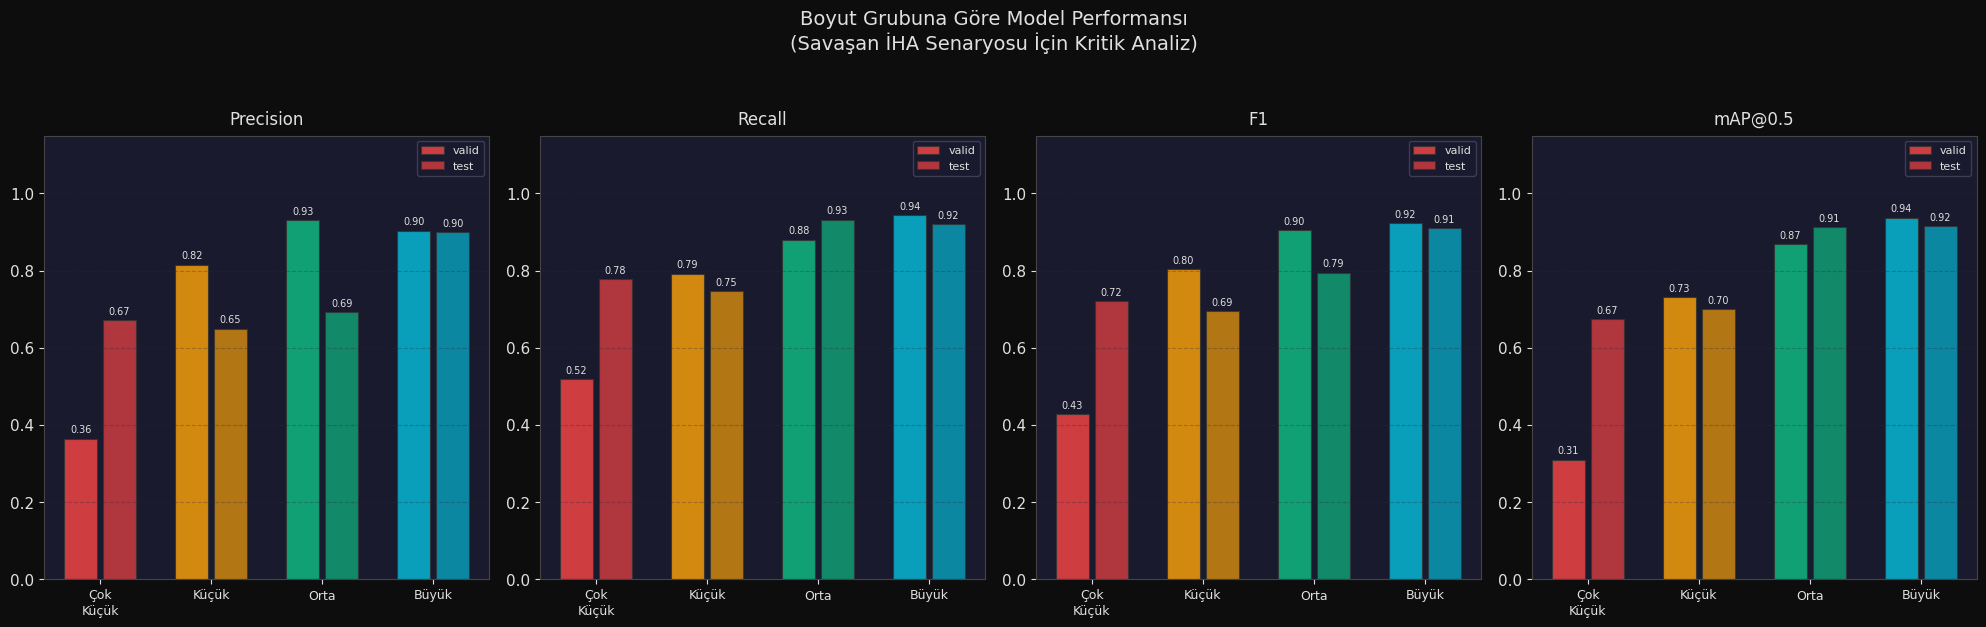

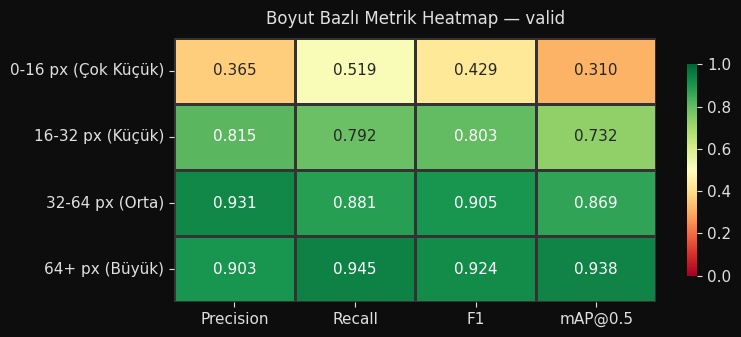

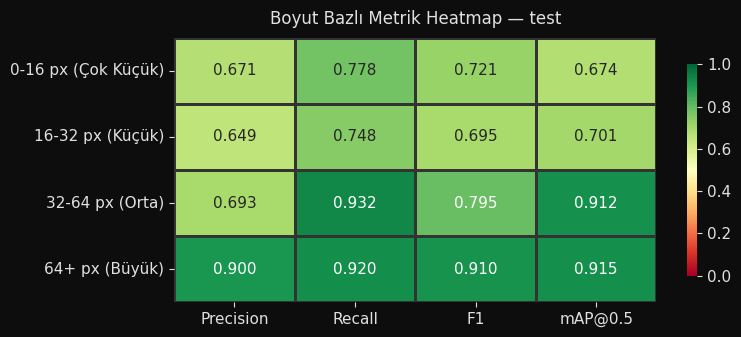

In [22]:
# ============================================================
#  BOYUT BAZLI METRİK GRAFİĞİ
# ============================================================

if df_size_all is not None and len(df_size_all) > 0:
    splits_in_data = df_size_all["Split"].unique()
    metrics_to_plot = ["Precision", "Recall", "F1", "mAP@0.5"]
    group_names = [name for name, _, _ in SIZE_BINS]

    fig, axes = plt.subplots(1, len(metrics_to_plot),
                            figsize=(5 * len(metrics_to_plot), 6))
    fig.patch.set_facecolor("#0d0d0d")

    bar_colors = {
        "0-16 px (Çok Küçük)": "#ef4444",
        "16-32 px (Küçük)":    "#f59e0b",
        "32-64 px (Orta)":     "#10b981",
        "64+ px (Büyük)":      "#06b6d4",
    }

    for ax, metric in zip(axes, metrics_to_plot):
        x = np.arange(len(group_names))
        n_splits = len(splits_in_data)
        width = 0.7 / n_splits

        for si, split in enumerate(splits_in_data):
            df_split = df_size_all[df_size_all["Split"] == split]
            vals = []
            for gn in group_names:
                row = df_split[df_split["Boyut Grubu"] == gn]
                v = float(row[metric].values[0]) if len(row) > 0 else 0
                vals.append(v)

            colors = [bar_colors.get(gn, ACCENT) for gn in group_names]
            offset = si * width - (n_splits - 1) * width / 2
            bars = ax.bar(x + offset, vals, width=width * 0.85,
                         color=colors, edgecolor="#333", linewidth=0.8,
                         label=split, alpha=0.85 - si * 0.15)

            for bar_obj, val in zip(bars, vals):
                if val > 0:
                    ax.text(bar_obj.get_x() + bar_obj.get_width() / 2,
                            bar_obj.get_height() + 0.01,
                            f"{val:.2f}", ha="center", va="bottom",
                            fontsize=7, color="#e0e0e0")

        ax.set_xticks(x)
        ax.set_xticklabels(["Çok\nKüçük", "Küçük", "Orta", "Büyük"],
                           fontsize=9)
        ax.set_ylim(0, 1.15)
        ax.set_title(metric, fontsize=12, pad=8)
        ax.grid(axis="y", alpha=0.3)
        if n_splits > 1:
            ax.legend(fontsize=8, framealpha=0.2)

    plt.suptitle("Boyut Grubuna Göre Model Performansı\n"
                 "(Savaşan İHA Senaryosu İçin Kritik Analiz)",
                 fontsize=14, y=1.04)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/size_based_metrics.png", dpi=150,
                bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()

    # --- Heatmap ---
    for split in splits_in_data:
        df_hm = df_size_all[df_size_all["Split"] == split].copy()
        df_hm = df_hm.set_index("Boyut Grubu")
        hm_data = df_hm[["Precision", "Recall", "F1", "mAP@0.5"]]

        fig, ax = plt.subplots(figsize=(8, 3.5))
        fig.patch.set_facecolor("#0d0d0d")
        sns.heatmap(hm_data.astype(float), annot=True, fmt=".3f",
                    cmap="RdYlGn", vmin=0, vmax=1,
                    linewidths=1, linecolor="#333",
                    cbar_kws={"shrink": 0.8}, ax=ax)
        ax.set_title(f"Boyut Bazlı Metrik Heatmap — {split}",
                     fontsize=12, pad=10)
        ax.set_ylabel("")
        plt.tight_layout()
        plt.savefig(f"{OUTPUT_DIR}/size_heatmap_{split}.png", dpi=150,
                    bbox_inches="tight", facecolor=fig.get_facecolor())
        plt.show()

In [23]:
# ============================================================
#  BOYUT BAZLI METRİK CSV EXPORT
# ============================================================

if df_size_all is not None:
    csv_size = f"{OUTPUT_DIR}/metrics_by_size.csv"
    df_size_all.to_csv(csv_size, index=False)
    print(f"✅ Boyut bazlı metrikler kaydedildi: {csv_size}")
else:
    print("⚠️  Boyut bazlı metrik kaydedilemedi — veri yok.")

✅ Boyut bazlı metrikler kaydedildi: sonuclar/metrics_by_size.csv


---
## 🧪 Bölüm 4 — Test Seti Değerlendirmesi & Karşılaştırma

In [24]:
# ============================================================
#  TEST SET — model.val(split='test')
# ============================================================
test_img_dir = DATASET_PATH / "test" / "images"
if not test_img_dir.exists() or len(list(test_img_dir.glob("*"))) == 0:
    print("⚠️  Test klasörü boş veya bulunamadı. Bu bölüm atlanıyor.")
    test_metrics = None
    df_test_cls  = None
else:
    print("🔍 Test seti değerlendiriliyor...\n")
    test_results = model.val(
        data    = str(yaml_path),
        split   = "test",
        imgsz   = IMGSZ,
        conf    = CONF_THRESHOLD,
        iou     = IOU_THRESHOLD,
        batch   = BATCH_SIZE,
        device  = DEVICE,
        plots   = True,
        verbose = True,
    )
    test_metrics = extract_metrics(test_results, "test")
    df_test_cls  = per_class_metrics(test_results, "test")
    print("\n✅ Test değerlendirmesi tamamlandı!")

🔍 Test seti değerlendiriliyor...

Ultralytics 8.4.51  Python-3.10.20 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
val: Fast image access  (ping: 0.10.1 ms, read: 158.479.5 MB/s, size: 21.9 KB)
val: Scanning C:\Users\ASUS\OneDrive\Masaüstü\dataset\test\labels.cache... 1265 images, 214 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1265/1265  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 80/80 2.2it/s 36.7s0.4ss
                   all       1265       1160      0.882      0.896      0.908      0.716
Speed: 2.8ms preprocess, 18.5ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to C:\Users\ASUS\OneDrive\Masast\Test\analiz5\runs\detect\val-2

✅ Test değerlendirmesi tamamlandı!


In [25]:
# ============================================================
#  TRAIN METRİKLERİ (isteğe bağlı — results.csv varsa çek)
# ============================================================
train_metrics = None

# Eğer kullanıcı train sırasında kaydedilmiş results.csv sağlarsa buraya yolu girin:
TRAIN_RESULTS_CSV = None  # ör: r"runs/detect/train/results.csv"

if TRAIN_RESULTS_CSV and Path(TRAIN_RESULTS_CSV).exists():
    df_train_log = pd.read_csv(TRAIN_RESULTS_CSV)
    df_train_log.columns = df_train_log.columns.str.strip()
    last = df_train_log.iloc[-1]

    # Ultralytics results.csv sütun isimlerini map et
    col_map = {
        "metrics/precision(B)": "Precision",
        "metrics/recall(B)"   : "Recall",
        "metrics/mAP50(B)"    : "mAP@0.5",
        "metrics/mAP50-95(B)" : "mAP@0.5:0.95",
    }
    train_metrics = {"Split": "train"}
    for src, dst in col_map.items():
        train_metrics[dst] = round(float(last.get(src, float('nan'))), 4)

    mp = train_metrics.get("Precision", 0)
    mr = train_metrics.get("Recall", 0)
    train_metrics["F1"] = round(2 * mp * mr / (mp + mr + 1e-9), 4)
    train_metrics.setdefault("mAP@0.5:0.95", float('nan'))
    for sp in ["Preprocess (ms)", "Inference (ms)", "Postprocess (ms)"]:
        train_metrics[sp] = float('nan')

    print("✅ Train metrikleri yüklendi (son epoch):")
    for k, v in train_metrics.items():
        print(f"   {k:<20}: {v}")
else:
    print("ℹ️  Train results.csv sağlanmadı — karşılaştırma sadece Valid/Test üzerinden yapılacak.")
    print("   Eğer train sonuçlarını da karşılaştırmak isterseniz:\n"
          "   TRAIN_RESULTS_CSV = r'runs/detect/train/results.csv' şeklinde ayarlayın.")

ℹ️  Train results.csv sağlanmadı — karşılaştırma sadece Valid/Test üzerinden yapılacak.
   Eğer train sonuçlarını da karşılaştırmak isterseniz:
   TRAIN_RESULTS_CSV = r'runs/detect/train/results.csv' şeklinde ayarlayın.


In [26]:
# ============================================================
#  KARŞILAŞTIRMA TABLOSU — Train / Valid / Test
# ============================================================
all_metrics = [m for m in [train_metrics, val_metrics, test_metrics] if m is not None]
df_compare  = pd.DataFrame(all_metrics).set_index("Split")

print("\n📊 Karşılaştırma Tablosu:")
display(df_compare.style.background_gradient(
    cmap="RdYlGn",
    subset=[c for c in ["Precision", "Recall", "F1", "mAP@0.5", "mAP@0.5:0.95"] if c in df_compare.columns]
))


📊 Karşılaştırma Tablosu:


,Precision,Recall,F1,mAP@0.5,mAP@0.5:0.95,Preprocess (ms),Inference (ms),Postprocess (ms)
Split,,,,,,,,
valid,0.920800,0.900600,0.910600,0.901600,0.648900,4.000000,18.550000,1.900000
test,0.882100,0.896300,0.889100,0.908000,0.716500,2.850000,18.460000,1.690000


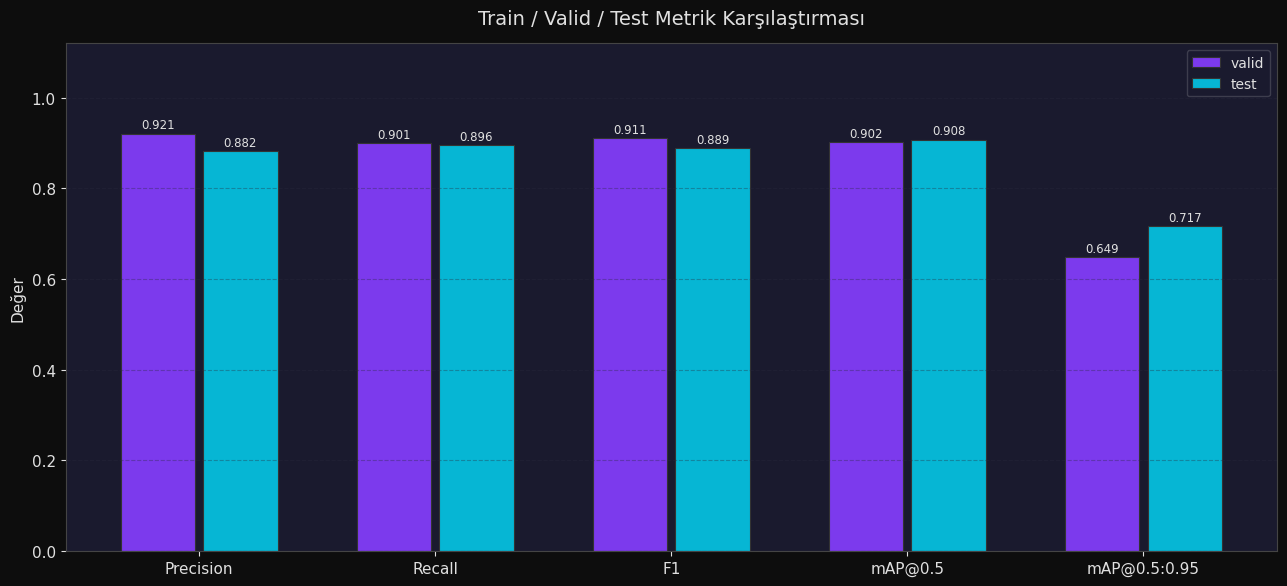

In [27]:
# ============================================================
#  KARŞILAŞTIRMA GRAFİĞİ
# ============================================================
metric_cols = [c for c in ["Precision", "Recall", "F1", "mAP@0.5", "mAP@0.5:0.95"] if c in df_compare.columns]

fig, ax = plt.subplots(figsize=(13, 6))
fig.patch.set_facecolor("#0d0d0d")

x     = np.arange(len(metric_cols))
n_sp  = len(df_compare)
width = 0.7 / n_sp

for i, (split_name, row) in enumerate(df_compare.iterrows()):
    vals  = [row.get(m, 0) for m in metric_cols]
    bars  = ax.bar(x + i * width - (n_sp-1)*width/2, vals,
                   width=width*0.9, label=split_name,
                   color=COLORS[i], edgecolor="#333", linewidth=0.8)
    for bar, val in zip(bars, vals):
        if not np.isnan(val):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                    f"{val:.3f}", ha="center", va="bottom", fontsize=8.5, color="#e0e0e0")

ax.set_xticks(x)
ax.set_xticklabels(metric_cols, fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Değer")
ax.set_title("Train / Valid / Test Metrik Karşılaştırması", fontsize=14, pad=14)
ax.legend(framealpha=0.2, fontsize=10)
ax.grid(axis="y", alpha=0.35)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/comparison_bar.png", dpi=150, bbox_inches="tight",
            facecolor=fig.get_facecolor())
plt.show()

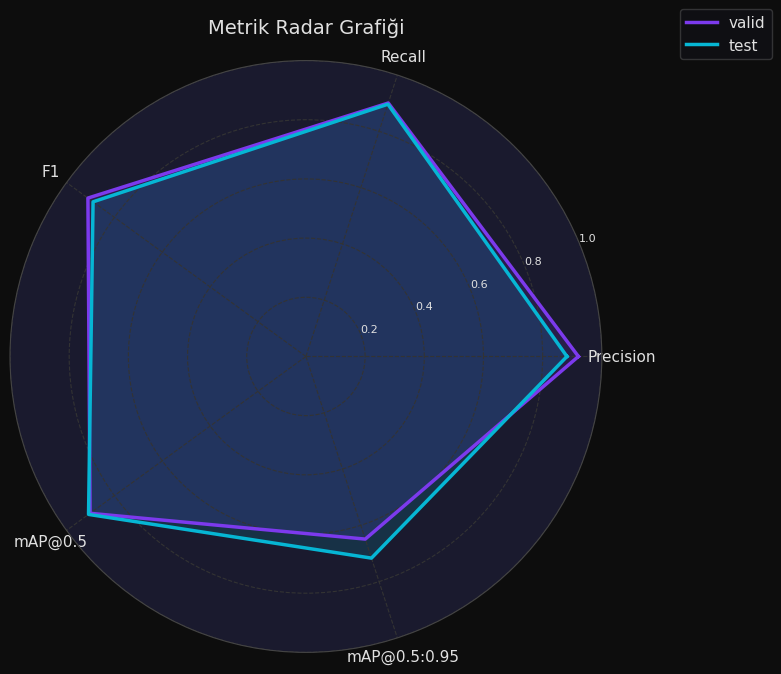

In [28]:
# ============================================================
#  RADAR / SPIDER GRAFİĞİ
# ============================================================
from matplotlib.patches import FancyArrowPatch

radar_metrics = ["Precision", "Recall", "F1", "mAP@0.5", "mAP@0.5:0.95"]
radar_metrics = [m for m in radar_metrics if m in df_compare.columns]
N = len(radar_metrics)

angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]  # kapat

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"polar": True})
fig.patch.set_facecolor("#0d0d0d")
ax.set_facecolor("#1a1a2e")

for i, (split_name, row) in enumerate(df_compare.iterrows()):
    vals = [row.get(m, 0) for m in radar_metrics]
    vals = [v if not np.isnan(v) else 0 for v in vals]
    vals += vals[:1]
    ax.plot(angles, vals, color=COLORS[i], linewidth=2.5, label=split_name)
    ax.fill(angles, vals, color=COLORS[i], alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_metrics, fontsize=11, color="#e0e0e0")
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=8, color="#888")
ax.grid(color="#333", linewidth=0.8)
ax.tick_params(colors="#e0e0e0")

ax.set_title("Metrik Radar Grafiği", fontsize=14, color="#e0e0e0", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1), framealpha=0.2)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/radar_chart.png", dpi=150, bbox_inches="tight",
            facecolor=fig.get_facecolor())
plt.show()

---
## ⚡ Bölüm 5 — Inference Hızı & Örnek Tahminler

In [29]:
# ============================================================
#  INFERENCE HIZI — ayrıntılı ölçüm
# ============================================================
speed_imgs = [f for f in (DATASET_PATH / "test" / "images").glob("*")
              if f.suffix.lower() in IMG_EXTS][:50]

if not speed_imgs:
    speed_imgs = [f for f in (DATASET_PATH / "valid" / "images").glob("*")
                  if f.suffix.lower() in IMG_EXTS][:50]

if speed_imgs:
    print(f"⏱️  {len(speed_imgs)} görüntü üzerinde hız testi yapılıyor...")

    # Warm-up
    _ = model.predict(str(speed_imgs[0]), imgsz=IMGSZ, conf=CONF_THRESHOLD,
                      device=DEVICE, verbose=False)

    timings = []
    for img_path in tqdm(speed_imgs):
        t0 = time.perf_counter()
        results_tmp = model.predict(str(img_path), imgsz=IMGSZ, conf=CONF_THRESHOLD,
                                    device=DEVICE, verbose=False)
        t1 = time.perf_counter()
        timings.append((t1 - t0) * 1000)  # ms

    mean_ms  = np.mean(timings)
    std_ms   = np.std(timings)
    min_ms   = np.min(timings)
    max_ms   = np.max(timings)
    fps      = 1000 / mean_ms

    print(f"\n⚡ Inference Hız Sonuçları ({len(speed_imgs)} görüntü):")
    print(f"   Ortalama    : {mean_ms:.2f} ms/görüntü")
    print(f"   Std Dev     : {std_ms:.2f} ms")
    print(f"   Min         : {min_ms:.2f} ms")
    print(f"   Max         : {max_ms:.2f} ms")
    print(f"   FPS         : {fps:.1f}")

    # Ultralytics detaylı hız
    ul_speed = val_metrics
    print(f"\n   Ultralytics Hız Dökümü (val seti):")
    print(f"   Preprocess  : {ul_speed.get('Preprocess (ms)', 'N/A')} ms")
    print(f"   Inference   : {ul_speed.get('Inference (ms)', 'N/A')} ms")
    print(f"   Postprocess : {ul_speed.get('Postprocess (ms)', 'N/A')} ms")
else:
    print("⚠️  Hız testi için görüntü bulunamadı.")
    timings = []
    mean_ms = fps = None

⏱️  50 görüntü üzerinde hız testi yapılıyor...


100%|██████████| 50/50 [00:01<00:00, 25.94it/s]


⚡ Inference Hız Sonuçları (50 görüntü):
   Ortalama    : 38.18 ms/görüntü
   Std Dev     : 7.35 ms
   Min         : 29.13 ms
   Max         : 61.17 ms
   FPS         : 26.2

   Ultralytics Hız Dökümü (val seti):
   Preprocess  : 4.0 ms
   Inference   : 18.55 ms
   Postprocess : 1.9 ms


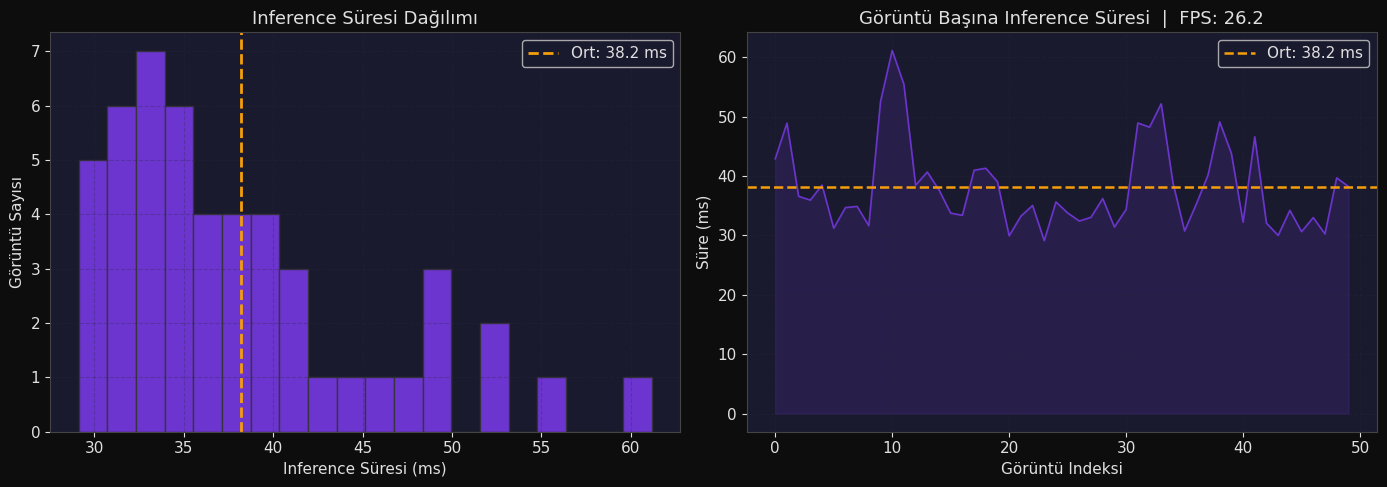

In [30]:
# ============================================================
#  INFERENCE HIZI GRAFİĞİ
# ============================================================
if timings:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.patch.set_facecolor("#0d0d0d")

    # Histogram
    ax = axes[0]
    ax.hist(timings, bins=20, color=ACCENT, edgecolor="#333", alpha=0.85)
    ax.axvline(mean_ms, color="#f59e0b", linewidth=2, linestyle="--", label=f"Ort: {mean_ms:.1f} ms")
    ax.set_xlabel("Inference Süresi (ms)")
    ax.set_ylabel("Görüntü Sayısı")
    ax.set_title("Inference Süresi Dağılımı", fontsize=13)
    ax.legend()
    ax.grid(alpha=0.3)

    # Line
    ax2 = axes[1]
    ax2.plot(timings, color=ACCENT, linewidth=1.2, alpha=0.8)
    ax2.axhline(mean_ms, color="#f59e0b", linewidth=1.8, linestyle="--", label=f"Ort: {mean_ms:.1f} ms")
    ax2.fill_between(range(len(timings)), timings, alpha=0.15, color=ACCENT)
    ax2.set_xlabel("Görüntü Indeksi")
    ax2.set_ylabel("Süre (ms)")
    ax2.set_title(f"Görüntü Başına Inference Süresi  |  FPS: {fps:.1f}", fontsize=13)
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/inference_speed.png", dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()

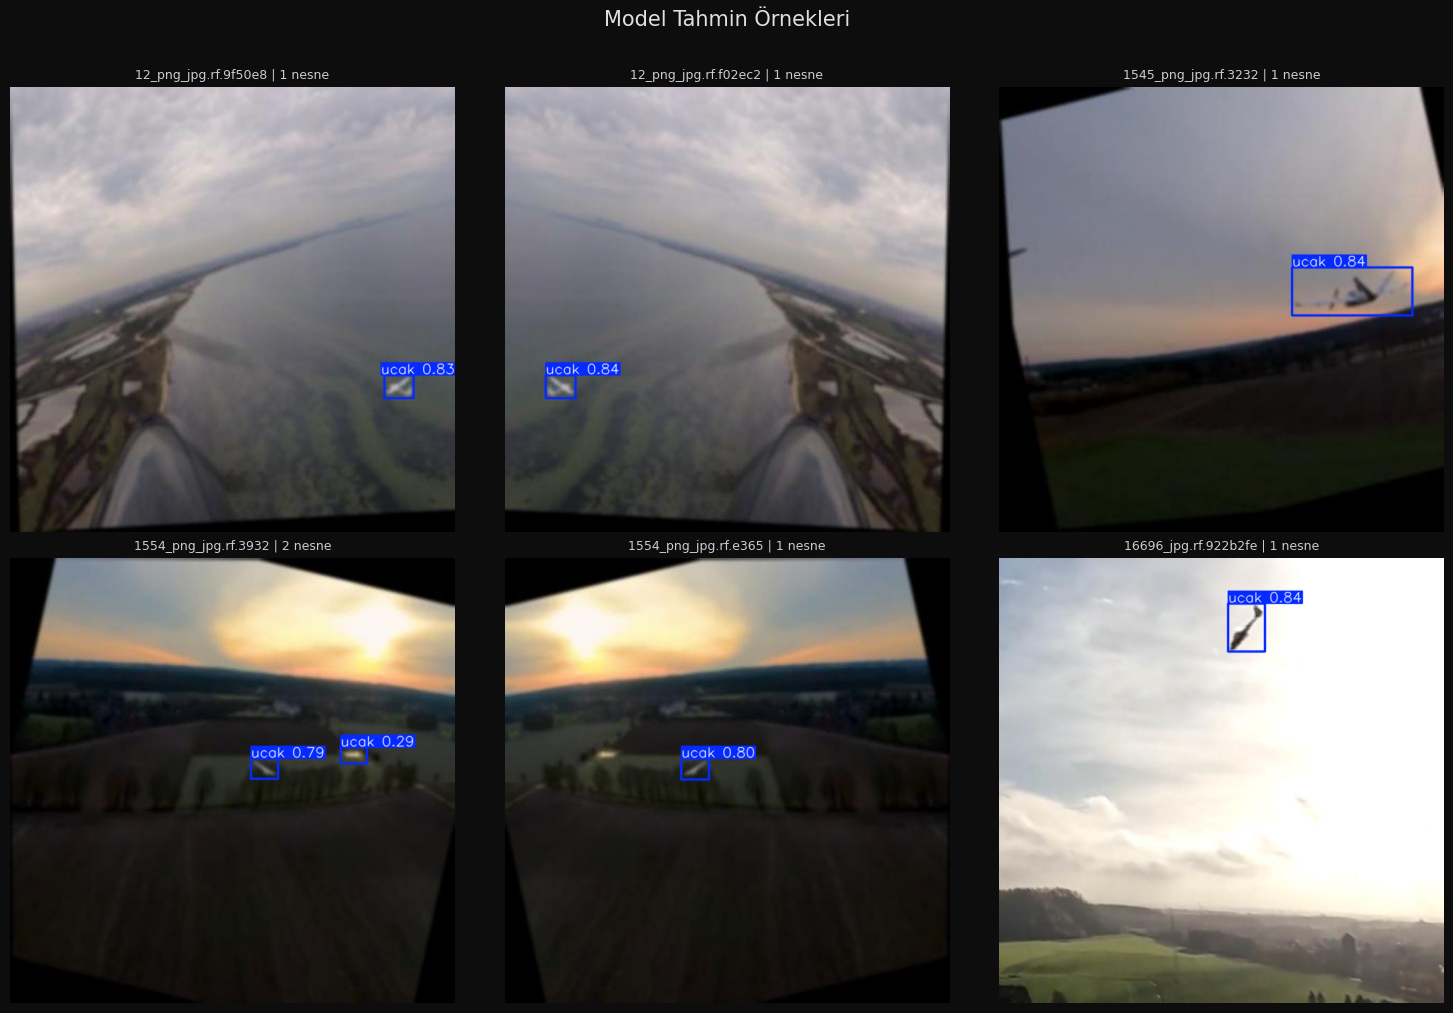

In [31]:
# ============================================================
#  ÖRNEK TAHMİNLER — test setinden 6 görüntü
# ============================================================
pred_imgs = speed_imgs[:6]

if pred_imgs:
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.patch.set_facecolor("#0d0d0d")
    fig.suptitle("Model Tahmin Örnekleri", fontsize=15, color="#e0e0e0", y=1.01)

    for ax, img_path in zip(axes.flat, pred_imgs):
        res = model.predict(str(img_path), imgsz=IMGSZ, conf=CONF_THRESHOLD,
                            device=DEVICE, verbose=False)[0]
        ann = res.plot()
        ann_rgb = ann[:, :, ::-1]  # BGR → RGB
        ax.imshow(ann_rgb)
        n_det = len(res.boxes) if res.boxes is not None else 0
        ax.set_title(f"{img_path.name[:20]} | {n_det} nesne", fontsize=9, color="#ccc")
        ax.axis("off")

    for ax in axes.flat[len(pred_imgs):]:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/predictions.png", dpi=120, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
else:
    print("⚠️  Tahmin görseli oluşturulacak görüntü bulunamadı.")

---
## 📋 Bölüm 6 — Özet Rapor & CSV Export

In [32]:
# ============================================================
#  ÖZET RAPOR TABLOSU
# ============================================================
from IPython.display import HTML

# Model bilgileri
model_summary = {
    "Model Dosyası"       : Path(MODEL_PATH).name,
    "Sınıf Sayısı"        : model.model.nc,
    "Sınıflar"            : ", ".join(CLASS_NAMES),
    "Toplam Parametre"    : f"{total_params:,}",
    "Görüntü Boyutu"      : IMGSZ,
    "Conf Threshold"      : CONF_THRESHOLD,
    "IoU Threshold"       : IOU_THRESHOLD,
}

# Dataset özeti
dataset_summary = {f"{s} Görüntü" : split_data[s]["images"] for s in splits}
dataset_summary["Toplam Görüntü"] = total_imgs

# Hız özeti
speed_summary = {}
if timings:
    speed_summary = {
        "Ortalama Inference" : f"{mean_ms:.2f} ms",
        "FPS"                : f"{fps:.1f}",
    }

print("=" * 60)
print("   YOLO11 MODEL DEĞERLENDİRME RAPORU")
print("=" * 60)
print("\n📌 Model Bilgileri:")
for k, v in model_summary.items():
    print(f"   {k:<25}: {v}")
print("\n📌 Dataset:")
for k, v in dataset_summary.items():
    print(f"   {k:<25}: {v}")
print("\n📌 Metrikler:")
display(df_compare)
if speed_summary:
    print("\n📌 Hız:")
    for k, v in speed_summary.items():
        print(f"   {k:<25}: {v}")
print("\n" + "=" * 60)

   YOLO11 MODEL DEĞERLENDİRME RAPORU

📌 Model Bilgileri:
   Model Dosyası            : 04.08_epoch130.pt
   Sınıf Sayısı             : 1
   Sınıflar                 : ucak
   Toplam Parametre         : 9,428,179
   Görüntü Boyutu           : 640
   Conf Threshold           : 0.25
   IoU Threshold            : 0.6

📌 Dataset:
   train Görüntü            : 10115
   valid Görüntü            : 1264
   test Görüntü             : 1265
   Toplam Görüntü           : 12644

📌 Metrikler:


,Precision,Recall,F1,mAP@0.5,mAP@0.5:0.95,Preprocess (ms),Inference (ms),Postprocess (ms)
Split,,,,,,,,
valid,0.9208,0.9006,0.9106,0.9016,0.6489,4.00,18.55,1.90
test,0.8821,0.8963,0.8891,0.9080,0.7165,2.85,18.46,1.69



📌 Hız:
   Ortalama Inference       : 38.18 ms
   FPS                      : 26.2



In [33]:
# ============================================================
#  PER-CLASS TABLO — tüm split'ler
# ============================================================
all_cls_dfs = []
for split_name, df_cls in [("valid", df_val_cls), ("test", df_test_cls)]:
    if df_cls is not None:
        df_tmp = df_cls.copy()
        df_tmp.insert(0, "Split", split_name)
        all_cls_dfs.append(df_tmp)

if all_cls_dfs:
    df_all_cls = pd.concat(all_cls_dfs, ignore_index=True)
    print("\n📋 Per-Class Metrikler (Tüm Split'ler):")
    display(df_all_cls.style.background_gradient(
        cmap="RdYlGn",
        subset=[c for c in ["Precision","Recall","F1","mAP@0.5","mAP@0.5:0.95"]
                if c in df_all_cls.columns]
    ))


📋 Per-Class Metrikler (Tüm Split'ler):


,Split,Sınıf,Precision,Recall,F1,mAP@0.5,mAP@0.5:0.95
0,valid,ucak,0.920800,0.900600,0.910600,0.901600,0.648900
1,test,ucak,0.882100,0.896300,0.889100,0.908000,0.716500


In [34]:
# ============================================================
#  CSV EXPORT
# ============================================================
# Genel metrikler
csv_compare = f"{OUTPUT_DIR}/metrics_comparison.csv"
df_compare.to_csv(csv_compare)
print(f"✅ Genel metrikler kaydedildi: {csv_compare}")

# Per-class metrikler
if all_cls_dfs:
    csv_perclass = f"{OUTPUT_DIR}/metrics_per_class.csv"
    df_all_cls.to_csv(csv_perclass, index=False)
    print(f"✅ Per-class metrikler kaydedildi: {csv_perclass}")

# Dataset özeti
df_dataset = pd.DataFrame(split_data).T
csv_dataset = f"{OUTPUT_DIR}/dataset_summary.csv"
df_dataset.to_csv(csv_dataset)
print(f"✅ Dataset özeti kaydedildi: {csv_dataset}")

# Hız sonuçları
if timings:
    df_speed = pd.DataFrame({
        "Metric": ["Mean (ms)", "Std (ms)", "Min (ms)", "Max (ms)", "FPS"],
        "Value" : [round(mean_ms,2), round(std_ms,2), round(min_ms,2), round(max_ms,2), round(fps,1)]
    })
    csv_speed = f"{OUTPUT_DIR}/inference_speed.csv"
    df_speed.to_csv(csv_speed, index=False)
    print(f"✅ Hız sonuçları kaydedildi: {csv_speed}")

print(f"\n🎉 Tüm çıktılar '{os.path.abspath(OUTPUT_DIR)}' klasöründe!")

✅ Genel metrikler kaydedildi: sonuclar/metrics_comparison.csv
✅ Per-class metrikler kaydedildi: sonuclar/metrics_per_class.csv
✅ Dataset özeti kaydedildi: sonuclar/dataset_summary.csv
✅ Hız sonuçları kaydedildi: sonuclar/inference_speed.csv

🎉 Tüm çıktılar 'c:\Users\ASUS\OneDrive\Masaüstü\Test\analiz5\sonuclar' klasöründe!


In [35]:
# ============================================================
#  KAYDEDILEN DOSYALARI LİSTELE
# ============================================================
print(f"\n📁 {OUTPUT_DIR}/ içindeki dosyalar:")
for f in sorted(Path(OUTPUT_DIR).glob("*")):
    size = f.stat().st_size
    print(f"   {'📊' if f.suffix == '.csv' else '🖼'} {f.name:<45} {size/1024:.1f} KB")


📁 sonuclar/ içindeki dosyalar:
   🖼 comparison_bar.png                            46.8 KB
   🖼 dataset_overview.png                          58.7 KB
   📊 dataset_summary.csv                           0.1 KB
   📊 inference_speed.csv                           0.1 KB
   🖼 inference_speed.png                           106.3 KB
   📊 metrics_by_size.csv                           0.6 KB
   📊 metrics_comparison.csv                        0.2 KB
   📊 metrics_per_class.csv                         0.1 KB
   🖼 predictions.png                               982.8 KB
   🖼 radar_chart.png                               140.2 KB
   🖼 sample_images.png                             1443.2 KB
   🖼 size_based_metrics.png                        82.0 KB
   🖼 size_distribution.png                         85.7 KB
   🖼 size_heatmap_test.png                         57.2 KB
   🖼 size_heatmap_valid.png                        59.8 KB
   🖼 val_curves.png                                28.9 KB


---

## ✅ Rapor Tamamlandı!

| Çıktı | Dosya |
|-------|-------|
| Genel metrik karşılaştırması | `eval_results/metrics_comparison.csv` |
| Per-class metrikler | `eval_results/metrics_per_class.csv` |
| Dataset özeti | `eval_results/dataset_summary.csv` |
| Inference hız sonuçları | `eval_results/inference_speed.csv` |
| Dataset görselleştirme | `eval_results/dataset_overview.png` |
| Confusion Matrix + Curves | `eval_results/val_curves.png` |
| Karşılaştırma bar grafiği | `eval_results/comparison_bar.png` |
| Radar grafiği | `eval_results/radar_chart.png` |
| Inference hız grafiği | `eval_results/inference_speed.png` |
| Örnek tahminler | `eval_results/predictions.png` |
